# ML - Obesidad infantil

Estructura local del proyecto:

```
ML_ObesidadInfantil/
├── data/          Obesidad_Infantil.csv
├── graphics/      gráficas generadas
├── models/        modelo_regresion_multiple.joblib
└── notebooks/     este notebook
```

Ejecuta las celdas en orden con **Shift + Enter**.

Antes de correr, activa el venv de Python 3.12 como kernel (arriba a la derecha, "Select Kernel").


In [1]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
#Crear dataframe
encoding = "latin1"
path = "../../data/Obesidad_Infantil.csv"
df = pd.read_csv(path, encoding=encoding)
print(df)

     PESO (KG)  TALLA (MT)  CIRCUNFERENCIA DE CINTURA  EDAD  \
0        18.25        1.00                       59.0     5   
1        14.70        1.06                       49.0     5   
2        16.45        1.06                       49.5     5   
3        13.55        1.07                       46.0     5   
4        16.95        1.07                       52.0     5   
..         ...         ...                        ...   ...   
308      73.60        1.58                       99.0    11   
309      52.40        1.60                       71.5    11   
310      63.20        1.60                       80.0    11   
311      96.20        1.60                      106.0    11   
312      74.45        1.65                       90.0    11   

     ÍNDICE CINTURA/TALLA    IMC SEXO  
0                    0.59  18.25    F  
1                    0.46  13.08    F  
2                    0.47  14.64    F  
3                    0.43  11.84    F  
4                    0.49  14.80    F  
.. 

**Modelo de Regression: **
Este modelo es un analisis que se realiza sobre datos numericos, que toma un conjunto de datos de entrada X (explicativas) y devuelve un conjunto de datos Y (predictiva).

In [3]:
 #1.- Asegurarme de usar unicamente valores numericos
print(df.info()) # Devuleve informacion del tipo de dato almacenado en cada columna

<class 'pandas.DataFrame'>
RangeIndex: 313 entries, 0 to 312
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PESO (KG)                  313 non-null    float64
 1   TALLA (MT)                 313 non-null    float64
 2   CIRCUNFERENCIA DE CINTURA  313 non-null    float64
 3   EDAD                       313 non-null    int64  
 4   ÍNDICE CINTURA/TALLA       313 non-null    float64
 5   IMC                        313 non-null    float64
 6   SEXO                       313 non-null    str    
dtypes: float64(5), int64(1), str(1)
memory usage: 17.2 KB
None


In [4]:
#Debemos excluir la varriable SEXO por no ser númerica
df_numeric = df.select_dtypes(include="number")
matrix_corrhn=df_numeric.corr() #.corr() es una funcion exclusiva de dataframes numericos
df_numeric

,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
0,18.25,1.00,59.0,5,0.59,18.25
1,14.70,1.06,49.0,5,0.46,13.08
2,16.45,1.06,49.5,5,0.47,14.64
3,13.55,1.07,46.0,5,0.43,11.84
4,16.95,1.07,52.0,5,0.49,14.80
...,...,...,...,...,...,...
308,73.60,1.58,99.0,11,0.63,29.48
309,52.40,1.60,71.5,11,0.45,20.47
310,63.20,1.60,80.0,11,0.50,24.69
311,96.20,1.60,106.0,11,0.66,37.58


In [5]:
df_numeric.columns

Index(['PESO (KG)', 'TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD',
       'ÍNDICE CINTURA/TALLA', 'IMC'],
      dtype='str')

In [6]:
#2.- Seleccionar las variables X y y
#Se decide que el modelo prediga los valores del PESO (KG)
y =  df_numeric ["PESO (KG)"] #Y ES UNA SERIE 
X = df_numeric [['TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD', 'ÍNDICE CINTURA/TALLA', 'IMC']] #DATAFRAME SE ANIDA DENTRO DE OTRA [[]] DONDE X ES UNA MATRIZ
print(y.shape, X.shape)

(313,) (313, 5)


In [7]:
#3.- Crear el modelo de Regresion 
model = LinearRegression()
type(model)

sklearn.linear_model._base.LinearRegression

In [8]:
#El modelo se ajusta a las variables
model.fit(X,y)

LinearRegression()

En este punto el modelo ya esta entrenado

In [9]:
b0=model.intercept_            #b0
bn=model.coef_                 #b1    (derivada)
print(b0,bn)

13.201515135054397 [-9.56194432e+00  1.26645570e+00 -1.65480041e-01 -1.65892138e+02
  1.80834974e+00]


y(est)= 13.20 -9.56X1 + 1.26X2 - 0.16X3 -165.89X4 + 1.80X5

In [10]:
#Primeras predicciones
y_pred = model.predict(X)           #El modelo predice a partir de datos que ya conoce
y_pred

array([12.65907819, 11.63761431, 13.43294638, 10.47703824, 13.47495938,
       14.82955741, 19.59530266, 12.48508663, 14.62695328, 18.68993826,
       15.20852307, 15.04705546, 15.74694059, 13.93944601, 21.4314582 ,
       19.05034568, 13.46654651, 19.53741058, 18.04185156, 26.00600439,
       17.43638544, 22.31236894, 18.14653075, 17.71986778, 16.70151523,
       20.69630388, 19.772183  , 22.18803068, 21.74735875, 19.62554531,
       20.2142009 , 14.03102495, 34.25067097, 17.69950153, 15.48861657,
       21.51472818, 19.81496529, 16.39476115, 25.50705433, 22.1930889 ,
       17.9890068 , 24.92807698, 17.38688012, 21.34247867, 17.40957603,
       20.1388253 , 22.29365936, 33.5594567 , 21.46053462, 20.0801317 ,
       18.38950777, 19.00510553, 20.40351697, 26.37047113, 22.88855226,
       22.53028386, 21.53220409, 20.59783347, 19.10901544, 20.86114497,
       17.13117323, 24.69298391, 23.73455855, 21.58428663, 20.1486439 ,
       22.07684803, 25.62745083, 32.61637867, 24.49423474, 25.98

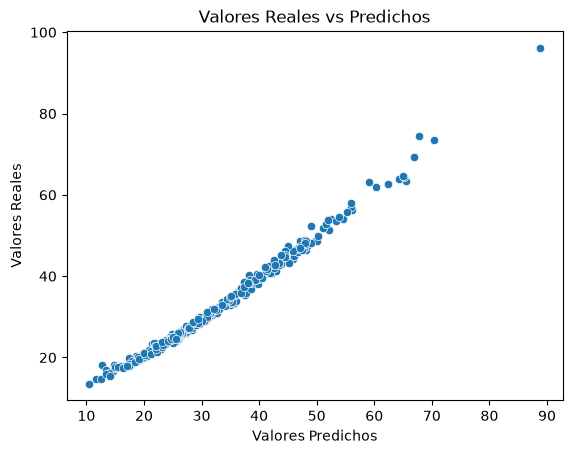

In [11]:
#Graficar la precision de las predicciones
sns.scatterplot(x=y_pred, y=y)
plt.title("Valores Reales vs Predichos")
plt.xlabel("Valores Predichos")
plt.ylabel("Valores Reales")
plt.show()

In [12]:
#Calcular metricas
r2=r2_score(y,y_pred)
mae = mean_absolute_error(y,y_pred)
mse= mean_squared_error(y,y_pred)
print(f"Valor de r2={r2}, Valor de mae={mae}, Valor de mse={mse}")

Valor de r2=0.988734894322405, Valor de mae=0.9074696065034521, Valor de mse=1.6476804530624742


Observamos que a mayor cantidad de variables explicativas X existe un incremento en el valor de r2, de tal manera que ante un modelo de regresión multiple es muy prudente usar "r2 ajustado". 

In [13]:
#Definir los residuos
residuos= y - y_pred
print(residuos.shape)
residuos

(313,)


0      5.590922
1      3.062386
2      3.017054
3      3.072962
4      3.475041
         ...   
308    3.149420
309    3.400837
310    4.099334
311    7.404600
312    6.647271
Name: PESO (KG), Length: 313, dtype: float64

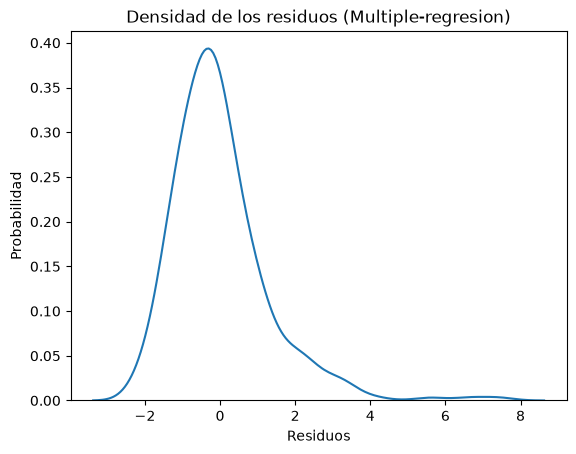

In [15]:
#1.- Graficar la distribución de los residuos
sns.kdeplot(residuos)
plt.title("Densidad de los residuos (Multiple-regresion)")
plt.xlabel("Residuos")
plt.ylabel("Probabilidad")
plt.savefig("../../graphics/densidad_residuos_multiple_regression.png")
plt.show()

Concluimos mediante el analisis de kdeplot que la distribucion de los resdiuos del modelo de regresion multiple presenta ruido, anormalidad en algunos residuos, tiene problemas de subestimación fuerte.

**Division de los datos y reajuste del modelo**

Principalmente para evitar metricas confunsas asociadas a "Sobreajuste"

In [16]:
from sklearn.model_selection import train_test_split

train_test_split principalmente me ayuda en la prevención de overfifting, se incluye en pipelines de desarrollo de deep learning.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42, test_size=0.2)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(250, 5) (63, 5) (250,) (63,)


In [18]:
X_train.head(10)

,TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
90,1.23,59.0,7,0.48,17.91
218,1.38,59.0,9,0.43,15.04
256,1.46,98.0,10,0.67,30.18
137,1.27,59.0,8,0.46,16.09
204,1.37,56.0,10,0.41,16.25
292,1.51,59.0,11,0.39,16.80
118,1.25,53.0,7,0.42,13.63
59,1.19,58.0,7,0.49,15.50
302,1.53,70.5,11,0.46,18.24
6,1.08,52.0,5,0.48,17.32


In [19]:
#Reajustar el modelo
model.fit(X_train, y_train)

LinearRegression()

In [20]:
y_pred= model.predict(X_test)
y_pred.shape

(63,)

In [21]:
residuos= y_test - y_pred
residuos

46     0.088715
9      1.585771
206   -1.141044
139   -0.772730
60     0.825793
         ...   
124   -1.266548
197   -1.463471
244   -0.391580
226   -0.263305
240   -0.829332
Name: PESO (KG), Length: 63, dtype: float64

In [22]:
r2_split = r2_score(y_test, y_pred)
mae_split = mean_absolute_error(y_test, y_pred)
mse_split = mean_squared_error(y_test, y_pred)
print(r2_split, mae_split, mse_split)

0.9855786502833768 0.9343554637397565 1.5842193485732137


train_split (youtube) y sobreajuste

**Guardar el modelo entrenado**
Se almacena en formato .joblib(estandar del scikitlearn) para ser retomado en otro notebook para analisis residual.

In [24]:
import joblib

#Empaquetar el modelo entrenado, sus metrticas y conjuntos de datos.
artifacts={
    "model": model,
    "features": list(X.columns),
    "X_train": X_train,
    "y_train": y_train,
    "y_test": y_test,
    "X_test": X_test,
    "metrics": {
        "r2": r2,
        "mae": mae,
        "mse": mse
    }
}

#Guardar
joblib.dump(artifacts,"../../models/exp01_ols_with_imc/multiple_regression.joblib")

['../../models/exp01_ols_with_imc/multiple_regression.joblib']